# Importamos librerías

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import IPython
from scipy.io import wavfile
from scipy.fft import rfft, rfftfreq, irfft

# Separación de señales usando Fourier (Gong)

Usando la transformada de Fourier en 1D, a partir del sonido mezclado del gong con el canto del pájaro, producimos una señal de audio en que se escuche principalmente el gong. Use una función de audio para esuchar esta señal.

In [2]:
!wget https://www.dropbox.com/scl/fi/rhjjsigirc6bdx9yfz5pf/gongpajaro.wav?rlkey=zz0lqzkwzfva8ahzgll7gw8x8 -O gongbird.wav -q

rate, gongbird_original = wavfile.read('gongbird.wav')

Sonido original

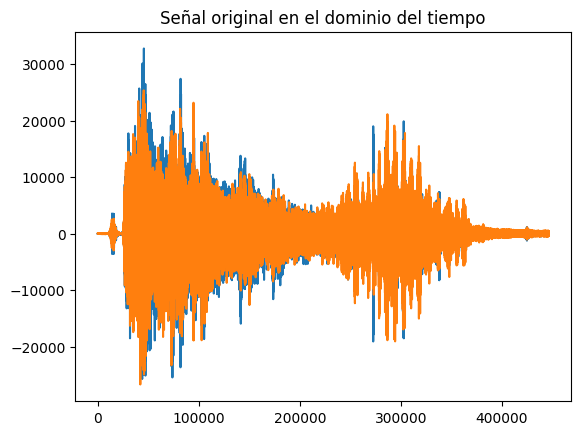

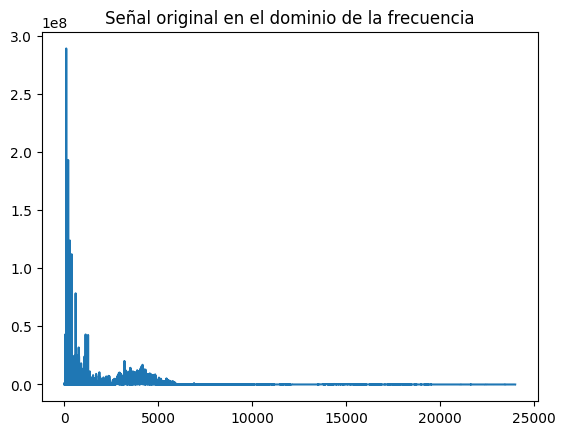

In [4]:
plt.plot(gongbird_original)
plt.title("Señal original en el dominio del tiempo")
plt.show()

gongbird_single_channel = gongbird_original[:, 0]  # seleccionamos el primer canal
N = len(gongbird_single_channel)
yfrequency = rfft(gongbird_single_channel)
xfrequency = rfftfreq(N, 1 / rate)

plt.plot(xfrequency, np.abs(yfrequency))
plt.title("Señal original en el dominio de la frecuencia")
plt.show()

IPython.display.Audio('gongbird.wav')

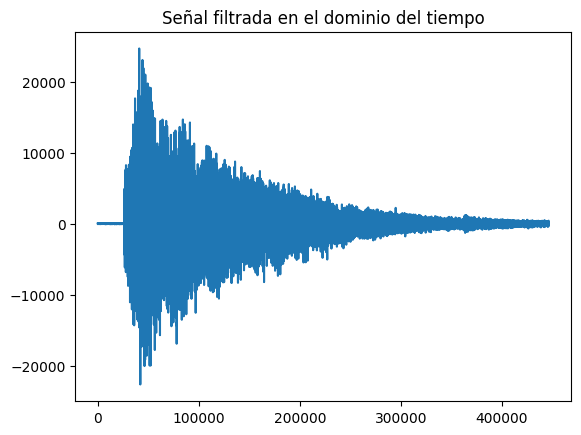

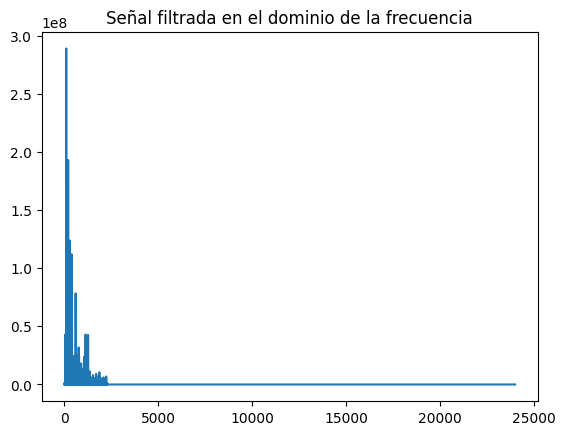

In [5]:
# Nyquist dice que la frecuencia máxima es la mitad del muestreo
points_per_freq = len(xfrequency) / (rate / 2)

frecuencia_maxima = int(points_per_freq * 2300)
filtro = np.ones((len(xfrequency),))
filtro[frecuencia_maxima:] = 0
yfiltrado = np.multiply(yfrequency,filtro)

gongbird_filtrado = irfft(yfiltrado).real


plt.plot(gongbird_filtrado)
plt.title("Señal filtrada en el dominio del tiempo")
plt.show()

plt.plot(xfrequency, np.abs(yfiltrado))
plt.title("Señal filtrada en el dominio de la frecuencia")
plt.show()

wavfile.write("gongbird_filtrado.wav", rate, gongbird_filtrado.astype(np.int16))


IPython.display.Audio('gongbird_filtrado.wav')


### Filtrado directo del canto del pájaro (Filtro Pasa-Altas)

Ahora, implementaremos un filtro pasa-altas para obtener directamente el canto del pájaro. Esto significa que las frecuencias bajas (donde reside el gong) serán atenuadas, y las frecuencias altas (donde está el pájaro) serán mantenidas.

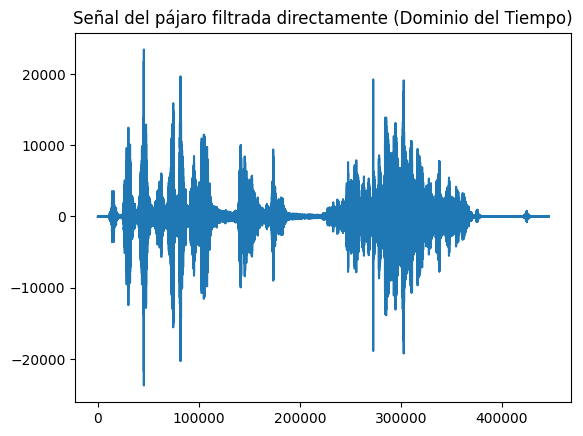

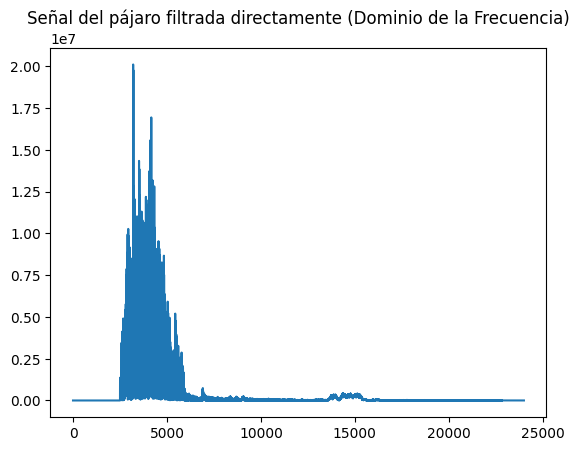

In [ ]:
frecuencia_corte_pajaro = int(points_per_freq * 2500) # Frecuencia de corte
# Crear un nuevo filtro (pasa-altas)
filtro_pajaro_directo = np.zeros((len(xfrequency),))
filtro_pajaro_directo[frecuencia_corte_pajaro:] = 1 # Mantenemos las frecuencias por encima del corte
yfiltrado_pajaro_directo = np.multiply(yfrequency, filtro_pajaro_directo)

sonido_pajaro_directo = irfft(yfiltrado_pajaro_directo, n=N).real

plt.plot(sonido_pajaro_directo)
plt.title("Señal del pájaro filtrada directamente (Dominio del Tiempo)")
plt.show()
plt.plot(xfrequency, np.abs(yfiltrado_pajaro_directo))
plt.title("Señal del pájaro filtrada directamente (Dominio de la Frecuencia)")
plt.show()

wavfile.write("sonido_pajaro_directo.wav", rate, sonido_pajaro_directo.astype(np.int16))
IPython.display.Audio('sonido_pajaro_directo.wav')